In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scqubits as scq

L_prime=400e-9
C_prime=160e-12
length=10e-3

velocity=1/(np.sqrt(L_prime*C_prime))
Z0=np.sqrt(L_prime/C_prime)
print(velocity)
print(Z0)

125000000.00000001
50.0


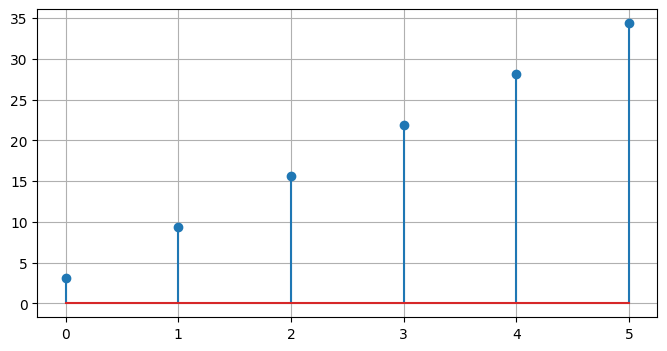

In [4]:
n_modes=6
n=np.arange(n_modes)
frequencies=(2*n+1)*velocity/(4*length)
frequencies_GHZ=frequencies/1e9
plt.figure(figsize=(8,4))
plt.stem(n,frequencies_GHZ)
plt.grid(True)
plt.show()

In [5]:
f_r_GHz=frequencies_GHZ[0]
resonator=scq.Oscillator(
    E_osc=f_r_GHz,
    truncated_dim=10
)
energies_GHz=resonator.eigenvals()
print(np.round(energies_GHz,4))

[ 0.     3.125  6.25   9.375 12.5   15.625]


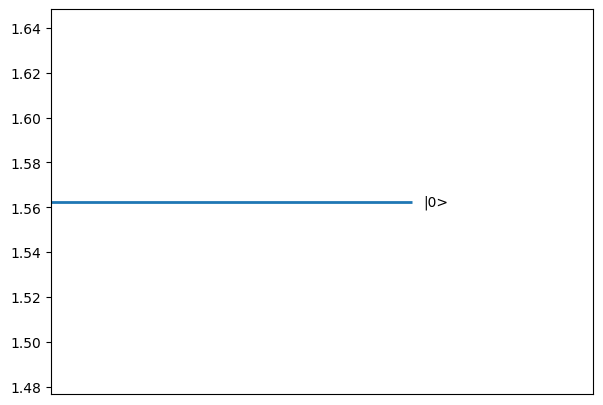

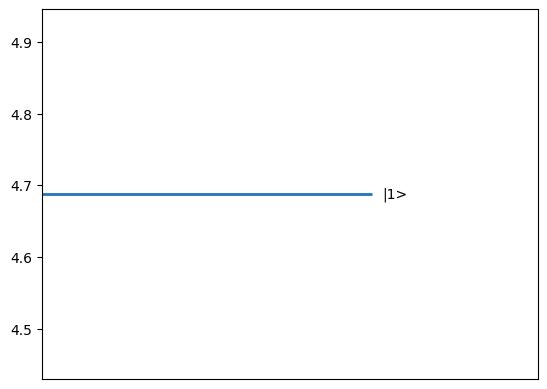

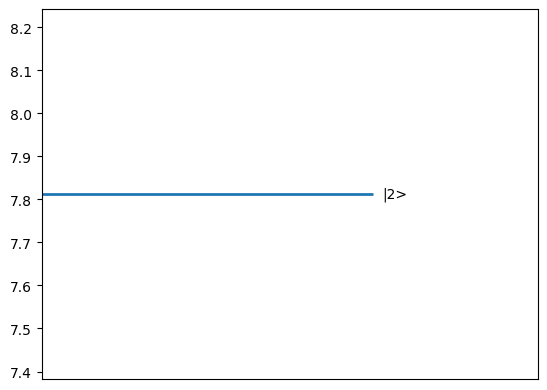

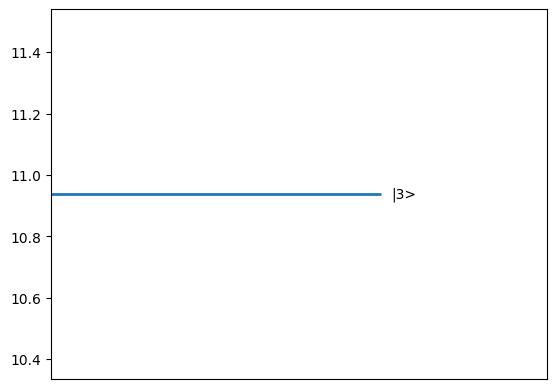

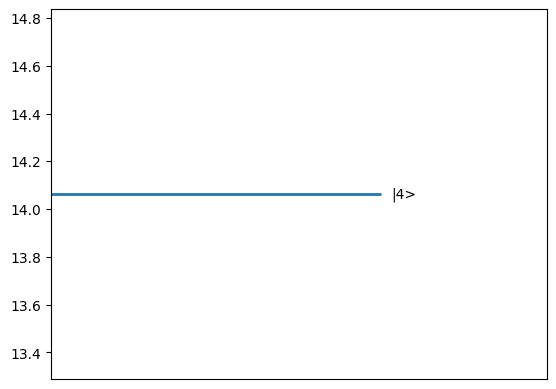

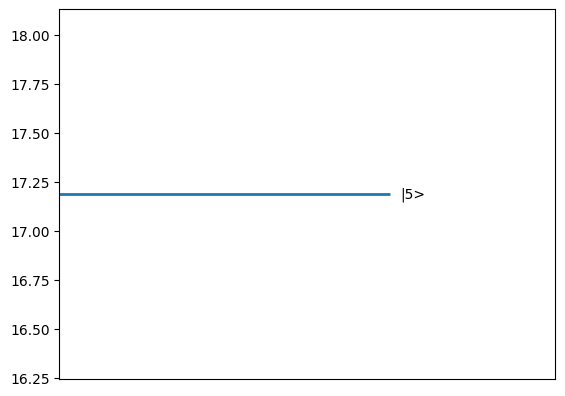

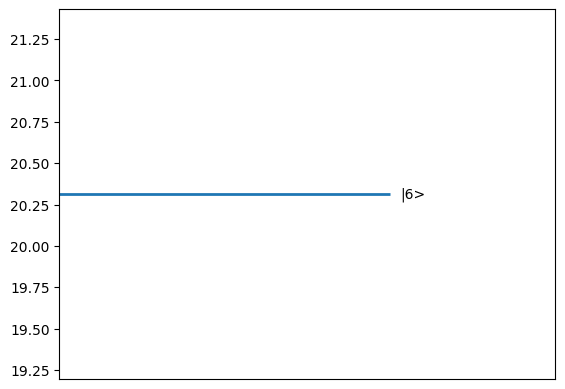

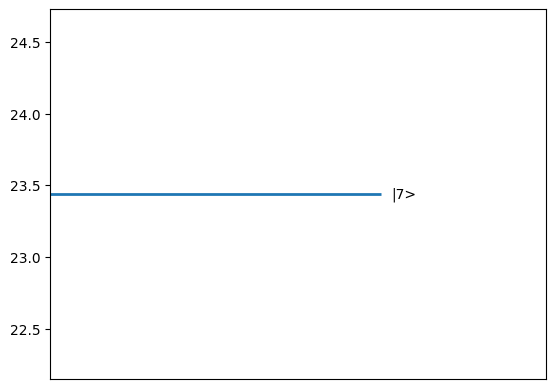

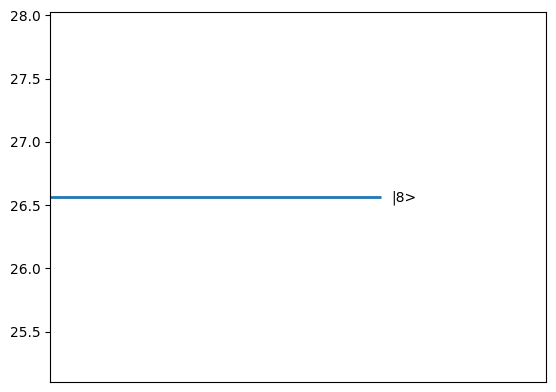

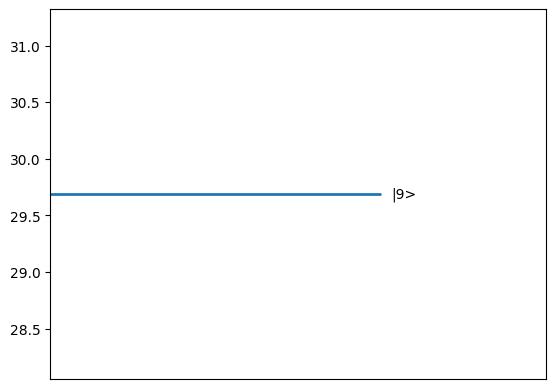

In [6]:
levels=np.arange(10)
E_over_h_GHz=f_r_GHz*(levels+0.5)
plt.figure(figsize=(7,5))
for m,energy in zip(levels,E_over_h_GHz):
  plt.hlines(energy,0,1,linewidth=2)
  plt.text(1.03,energy,f"|{m}>",va="center")
  plt.xlim(0,1.5)
  plt.xticks([])
  plt.show()

In [12]:
from scipy.linalg import eigvals
wr=2*np.pi*f_r_GHz
qubit=scq.Transmon(EJ=20.0,EC=0.25,ng=0.0,ncut=35)
qubit_energies=qubit.eigenvals(evals_count=3)
fq=qubit_energies[1]-qubit_energies[0]
g=0.08
N=8
a=np.diag(np.sqrt(np.arange(1,N)),1)
adag=a.conj().T
Iq=np.eye(2)
Ir=np.eye(N)
Hq=np.diag([0.0,fq])
Hr=f_r_GHz*(adag@a)
sm=np.array([[0,1],[0,0]],dtype=complex)
sp=sm.conj().T
H=(
    np.kron(Hq,Ir)+
    np.kron(Iq,Hr)+g*(np.kron(sp,a)+np.kron(sm,adag))
)
E=np.linalg.eigvalsh(H)
print(np.round(E[:8],4))

[ 0.      3.1228  6.0656  6.2457  9.1928  9.3685 12.32   12.4913]


In [2]:
!pip install scqubits

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 83.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 67.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scqubits]
